# Outlook

In this notebook we code a full version of the DQN algorithm, with a
**replay buffer** and a **target network**, and then extend it into
**Double-DQN**.

The DQN algorithm is explained in [this
video](https://www.youtube.com/watch?v=CXwvOMJujZk) and you can also read
[the corresponding slides](http://pages.isir.upmc.fr/~sigaud/teach/dqn.pdf).

Compared with the previous notebook, we:

- learn from a **replay buffer** of transitions instead of fresh episodes;
- use a **target network** for the bootstrap;
- use a better estimate of the maximum (**Double-DQN**).

## Setup

**On Colab**: run the installation cell below (generated automatically,
pinned versions). **Locally**: install the environment with `uv sync`, no
need for this cell.

In [1]:
import copy
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from dataclasses import dataclass, replace
from scipy import stats
from torch import Tensor
from torch.utils.tensorboard import SummaryWriter
from tqdm.auto import tqdm
from rl_mind.core import Action, Actor
from rl_mind.nn import build_mlp
from rl_mind.env import VecEnv
from rl_mind.data import ReplayBuffer, Transitions
from rl_mind.collectors import TransitionCollector
from rl_mind.evaluation import Evaluator
from rl_mind.notebook import run_directory, setup_tensorboard, silence_known_warnings


## The `rl_mind` toolkit

The `rl_mind` package ([documentation](https://pypi.org/project/rl-mind/)),
installed with the practicals, provides a small set of *typed* helpers used
throughout the RL notebooks. The ones used here:

- `VecEnv` runs several copies of a gymnasium environment in parallel;
- `Transitions` is a batch of $(s, a, r, s', \text{terminated})$ tuples,
  stored in a `ReplayBuffer`;
- `TransitionCollector` runs an actor in a `VecEnv` and returns the
  corresponding `Transitions`;
- `Evaluator` periodically evaluates an actor and keeps the best one;
- `Actor` is the base class of the policies (`actor(obs)` = training-time,
  `actor.act(obs)` = deterministic evaluation).

In [2]:
# pygame and tensorboard still use the deprecated `pkg_resources` API
silence_known_warnings()

# DQN

## Definition of the agents

The Q-network and the $\epsilon$-greedy policy are unchanged from the
previous notebook (`DiscreteQNetwork` outputs one value per action, `QPolicy`
turns it into an $\epsilon$-greedy actor).

In [3]:
class DiscreteQNetwork(nn.Module):
    """The action-value network $Q(s, \\cdot)$ for discrete actions"""

    def __init__(self, obs_dim: int, hidden: tuple[int, ...], n_actions: int):
        super().__init__()
        self.model = build_mlp([obs_dim, *hidden, n_actions])

    def forward(self, obs: Tensor) -> Tensor:
        return self.model(obs)

In [4]:
class QPolicy(Actor[Action]):
    """An $\\epsilon$-greedy policy over a `DiscreteQNetwork`"""

    def __init__(self, q_network: DiscreteQNetwork, epsilon: float):
        super().__init__()
        self.q_network = q_network
        self.epsilon = epsilon

    def forward(self, obs: Tensor) -> Action:
        q_values = self.q_network(obs)
        greedy = q_values.argmax(-1)
        random = torch.randint(q_values.shape[-1], (obs.shape[0],))
        explore = torch.rand(obs.shape[0]) < self.epsilon
        return Action(value=torch.where(explore, random, greedy))

    def act(self, obs: Tensor) -> Tensor:
        return self.q_network(obs).argmax(-1)

## The critic loss

Now that we learn from a **replay buffer**, the loss is computed on a flat
batch of transitions $(s, a, r, s', \text{terminated})$ — no time dimension,
no masking. The DQN target uses the **target network** $Q_{\theta'}$ for the
bootstrap:

$$ Y^{DQN} = r + \gamma\,(1-\text{terminated})\, \max_a Q_{\theta'}(s', a) $$

and we regress the online $Q_\theta(s, a)$ towards it.

In [36]:
def compute_dqn_loss(
    gamma: float,
    batch: Transitions[Action],
    q_network: DiscreteQNetwork,
    target_network: DiscreteQNetwork,
) -> Tensor:
    """Compute the DQN loss on a batch of transitions

    :param gamma: The discount factor
    :param batch: The batch of transitions
    :param q_network: The online network $Q_\\theta$ — the gradient flows
        through the $Q_\\theta(s, a)$ it computes
    :param target_network: The target network $Q_{\\theta'}$, used for the
        bootstrap only: its Q-values must be **detached**
    :return: The critic loss (a scalar)
    """
    # Compute the loss

    q_values = q_network(batch.obs)         # Q(s, .) from the online network
    q_sa = torch.gather(input=q_values, dim=1, index=batch.action.value.unsqueeze(-1)).squeeze(-1)             
    # Q(s, a) for the played actions
    # the bootstrap is detached: no gradient flows through the target
    with torch.no_grad():
        q_successors = target_network(batch.next_obs)
        q_max = q_successors.max(dim=1).values
        target = batch.reward + gamma * ~batch.terminated * q_max    # do not bootstrap when batch.terminated
    return ((target - q_sa) ** 2).mean()

## Hyper-parameters

In [7]:
@dataclass(frozen=True)
class DQNConfig:
    env_name: str = "CartPole-v1"
    seed: int = 4

    #: Total number of environment steps
    max_steps: int = 100_000
    #: Number of parallel training environments
    n_envs: int = 8
    #: Environment steps collected before each round of updates
    steps_per_round: int = 32
    #: Gradient updates per round
    updates_per_round: int = 32
    #: Steps before learning starts
    learning_starts: int = 5_000

    #: Replay buffer capacity, minibatch size
    buffer_size: int = 100_000
    batch_size: int = 256

    #: Exploration rate
    epsilon: float = 0.02
    #: Discount factor
    gamma: float = 0.99
    #: Steps between two hard target-network updates
    target_update_interval: int = 1_000
    max_grad_norm: float = 0.5

    hidden: tuple[int, ...] = (256, 256)
    lr: float = 1e-3

    #: Steps between two evaluations, and number of evaluation episodes
    eval_interval: int = 2_000
    n_eval_envs: int = 10

## Main training loop

`compute_loss` is passed in so we can reuse the loop for both DQN and, later,
Double-DQN: both take the same arguments (the batch and the two networks) and
compute the Q-values they need themselves. The target network is a copy of
the online network, refreshed (hard update) every `target_update_interval`
steps.

In [8]:
def run_dqn(cfg: DQNConfig, compute_loss, name: str = "dqn") -> Evaluator:
    """Train a DQN agent with a replay buffer and a target network

    :param cfg: The hyper-parameters
    :param compute_loss: The loss function, `compute_dqn_loss` or (later)
        `compute_ddqn_loss`
    :param name: The name of the run (for tensorboard)
    :return: The evaluator, which holds the evaluation history and the best
        policy found (`visualize_best()` shows it playing)
    """
    # Fix the random seed so that two runs with the same `cfg` give the same
    # result (network initialization, exploration, sampling from the buffer)
    torch.manual_seed(cfg.seed)

    # --- Setup

    # `n_envs` copies of the environment, stepped together
    env = VecEnv(cfg.env_name, cfg.n_envs, seed=cfg.seed)

    # The Q-network Q(s, .), and the target network: a *copy* of it (separate
    # parameters), which only changes when we copy the Q-network into it again
    # (see the end of the loop)
    q_network = DiscreteQNetwork(env.observation_dim, cfg.hidden, env.n_actions)
    target_network = copy.deepcopy(q_network)

    # The epsilon-greedy policy *wraps* the Q-network (no copy here): each
    # time the network is updated, the policy changes too
    policy = QPolicy(q_network, cfg.epsilon)

    # The optimizer only updates the Q-network: the target network is never
    # trained, just copied
    optimizer = torch.optim.Adam(q_network.parameters(), lr=cfg.lr)

    # The collector runs `policy` (with exploration) in `env` and returns
    # transitions (s, a, r, s', terminated) rather than full episodes; the
    # replay buffer stores the last `buffer_size` of them
    collector = TransitionCollector(env, policy)
    buffer = ReplayBuffer(cfg.buffer_size)

    # Logging: a directory for this run, and a tensorboard writer in it
    run_dir = run_directory(f"{name}-{cfg.env_name}-S{cfg.seed}")
    writer = SummaryWriter(run_dir)

    # The evaluator measures the *greedy* policy (`policy.act`, no
    # exploration) every `eval_interval` steps, on its own environments, and
    # keeps a copy of the best policy so far
    evaluator = Evaluator(
        VecEnv(cfg.env_name, cfg.n_eval_envs, seed=cfg.seed + 100),
        every=cfg.eval_interval,
        run_dir=run_dir,
        writer=writer,
    )

    # --- Training loop: one iteration = one round of collection + updates

    last_target_update = 0
    pbar = tqdm(total=cfg.max_steps)  # a progress bar, in environment steps
    while collector.steps < cfg.max_steps:
        # 1. Play `steps_per_round` steps with the current policy, and add
        # the resulting transitions to the buffer
        buffer.add(collector.collect(cfg.steps_per_round))
        pbar.update(collector.steps - pbar.n)

        # Do not learn before the buffer holds enough transitions: the first
        # minibatches would otherwise be drawn from a handful of transitions,
        # and the network would overfit them
        if len(buffer) < cfg.learning_starts:
            continue

        # 2. Several gradient steps, each on a minibatch drawn at random from
        # the buffer — mostly *old* transitions, played by earlier versions of
        # the policy (DQN is off-policy, so this is fine), and uncorrelated
        # (unlike the successive steps of an episode)
        for _ in range(cfg.updates_per_round):
            batch = buffer.sample(cfg.batch_size)
            critic_loss = compute_loss(cfg.gamma, batch, q_network, target_network)

            # Reset the gradients (PyTorch accumulates them otherwise),
            # back-propagate, clip the gradient norm (large gradients make DQN
            # unstable), and update the parameters
            optimizer.zero_grad()
            critic_loss.backward()
            torch.nn.utils.clip_grad_norm_(q_network.parameters(), cfg.max_grad_norm)
            optimizer.step()

        # 3. Hard update of the target network: every `target_update_interval`
        # steps, copy the Q-network's parameters into it. In between, the
        # regression target of the loss stays fixed, which stabilizes learning
        if collector.steps - last_target_update > cfg.target_update_interval:
            last_target_update = collector.steps
            target_network.load_state_dict(q_network.state_dict())

        # 4. Log the loss (of the last minibatch), and evaluate if
        # `eval_interval` steps have passed since the last evaluation (`result`
        # is `None` otherwise)
        writer.add_scalar("loss/critic", critic_loss.item(), collector.steps)
        if result := evaluator.run_if_needed(collector.steps, policy):
            pbar.set_description(
                f"eval={result.mean:6.1f} best={evaluator.best_reward:6.1f}"
            )

    pbar.close()
    return evaluator

## Launching tensorboard to visualize the results

In [9]:
setup_tensorboard()

Reusing TensorBoard on port 6006 (pid 312821), started 0:45:20 ago. (Use '!kill 312821' to kill it.)

In [37]:
cfg = DQNConfig()
dqn = run_dqn(cfg, compute_dqn_loss, name="dqn")

  0%|          | 0/100000 [00:00<?, ?it/s]

In [16]:
dqn.visualize_best()

# Double-DQN

In DQN the same (target) network both *selects* and *evaluates* the best next
action in the target, which leads to overestimation: an action whose value is
overestimated gets selected more often, slowing learning.

**Double-DQN** decouples the two. The target

$$Y^{DQN} = r + \gamma\, Q_{\theta'}\big(s', \arg\max_a Q_{\theta'}(s', a)\big)$$

becomes

$$Y^{DDQN} = r + \gamma\, Q_{\theta'}\big(s', \arg\max_a Q_{\theta}(s', a)\big)$$

i.e. the **online** network $Q_\theta$ selects the next action, while the
**target** network $Q_{\theta'}$ evaluates it.

Write `compute_ddqn_loss` below: it has the same signature as
`compute_dqn_loss`, and this time you need $Q_\theta(s', \cdot)$ *and*
$Q_{\theta'}(s', \cdot)$ — both detached, since neither takes a gradient.

In [41]:
def compute_ddqn_loss(
    gamma: float,
    batch: Transitions[Action],
    q_network: DiscreteQNetwork,
    target_network: DiscreteQNetwork,
) -> Tensor:
    """Compute the Double-DQN loss on a batch of transitions"""
    # Compute the loss

    q_values = q_network(batch.obs)
    q_sa = torch.gather(input=q_values, dim=1, index=batch.action.value.unsqueeze(-1)).squeeze(-1) 
    # the online network selects the next action, the target network evaluates it
    with torch.no_grad():
        inline_q_successors = q_network(batch.next_obs)
        a_max = inline_q_successors.argmax(dim=1)
        target_q_successors = target_network(batch.next_obs)
        target_q_sa = torch.gather(input=target_q_successors, dim=1, index=a_max.unsqueeze(-1)).squeeze(-1)
        target = batch.reward + gamma * (1 -batch.terminated.float()) * target_q_sa
    return ((target - q_sa) ** 2).mean()


In [42]:
ddqn_cfg = replace(DQNConfig(), seed=3, hidden=(128, 128))
ddqn = run_dqn(ddqn_cfg, compute_ddqn_loss, name="double-dqn")

  0%|          | 0/100000 [00:00<?, ?it/s]

In [32]:
ddqn.visualize_best()

## Comparing DQN and Double-DQN

We plot the two learning curves (mean cumulated reward ± std) and run a Welch
t-test on the final evaluations.

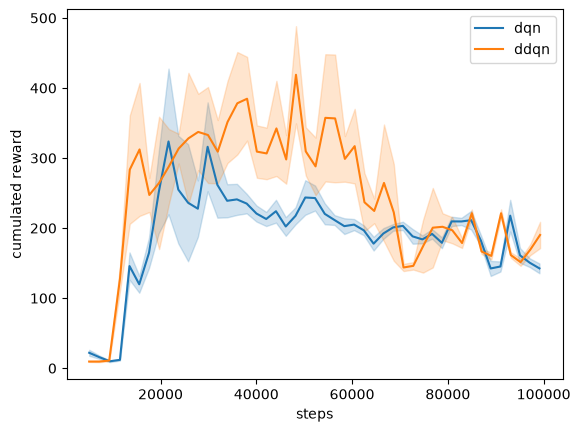

DQN vs Double-DQN (final evaluation): t=-7.52, p-value=0.000


In [40]:
def plot_evaluations(**evaluators: Evaluator):
    for name, evaluator in evaluators.items():
        steps = [result.step for result in evaluator.history]
        means = torch.tensor([result.mean for result in evaluator.history])
        stds = torch.tensor(
            [float(result.rewards.std()) for result in evaluator.history]
        )
        (line,) = plt.plot(steps, means, label=name)
        plt.fill_between(
            steps, means - stds, means + stds, alpha=0.2, color=line.get_color()
        )
    plt.xlabel("steps")
    plt.ylabel("cumulated reward")
    plt.legend()
    plt.show()


plot_evaluations(dqn=dqn, ddqn=ddqn)

welch = stats.ttest_ind(
    dqn.history[-1].rewards.numpy(), ddqn.history[-1].rewards.numpy(), equal_var=False
)
print(
    f"DQN vs Double-DQN (final evaluation): t={welch.statistic:.2f}, p-value={welch.pvalue:.3f}"
)